> **Bản PyTorch** của `examples/4. Training Utilities/2_Human_Gender_CNN.ipynb` (Keras). Người chuyển: TV2 – Lê Phan Nguyên Hải. Notebook khuôn của BTL03.
>
> **Thay đổi so với bản Keras**

> - Ảnh `(N, 64, 64, 1)` → `(N, 1, 64, 64)`; nhãn one-hot `.npy` → `argmax` thành chỉ số lớp.
> - Model viết bằng `nn.Sequential(OrderedDict(...))` (giữ tên lớp `conv1_1`, `pool1`, ... như Keras); 5 khối conv lặp lại gom vào hàm `conv_block`.
> - `Adam(lr=...)` → `torch.optim.Adam(lr=...)`; khởi tạo trọng số giống Keras (glorot_uniform). Dữ liệu giữ nguyên như bản gốc (không chuẩn hoá thêm).
> - `SVG(model_to_dot(...))` → in `summary`.
> - Callback Keras → PyTorch (PyTorch không có callback, viết trong vòng lặp `fit_with_callbacks`):
>   - `ModelCheckpoint(save_best_only=True)` → lớp `ModelCheckpoint` tự viết, lưu `state_dict` dạng `.pt` vào `checkpoints/`.
>   - `EarlyStopping(patience=5)` → lớp `EarlyStopping` tự viết.
>   - `ReduceLROnPlateau(factor=0.1, patience=5, min_lr=0.0001)` → `torch.optim.lr_scheduler.ReduceLROnPlateau`. PyTorch giảm LR khi số epoch không cải thiện *vượt quá* `patience`, Keras giảm khi *đạt* `patience`, nên truyền `patience - 1`.
>   - `TensorBoard(log_dir='./logs')` → `torch.utils.tensorboard.SummaryWriter('./logs')`.
> - `model.load_weights('000027-...hdf5')` → `model.load_state_dict(torch.load(<file .pt tốt nhất>))`. File `.hdf5` của bản gốc không có và PyTorch không nạp được, nên huấn luyện lại rồi nạp checkpoint của chính lần chạy này.
> - Ảnh `checkpoints.PNG`, `tfboard.PNG` của bản gốc → liệt kê thư mục `checkpoints/` và vẽ các đại lượng đã ghi vào TensorBoard.

# Overview
- ModelCheckpoint: save model while training
- EarlyStopping: stop training early to avoid overfitting
- ReduceLROnPlateau: reduce learning rate while training
- TensorBoard: plot training and validation metrics

# Import libraries

In [1]:
import os
import time
import numpy as np
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.utils.data import TensorDataset, DataLoader

SEED = 0
np.random.seed(SEED)
torch.manual_seed(SEED)
# cuDNN mặc định chọn thuật toán nhanh nhưng không tất định -> chạy lại cùng seed vẫn ra số hơi khác.
# Tắt để mỗi lần Run All cho cùng kết quả (chậm hơn một chút).
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

# Keras tự dùng GPU nếu có; PyTorch phải chọn thiết bị và chuyển model, dữ liệu sang thiết bị đó
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('torch', torch.__version__, '| device:', device, torch.cuda.get_device_name(0) if device.type == 'cuda' else '')
# Training utilities
from torch.utils.tensorboard import SummaryWriter

torch 2.6.0+cu124 | device: cuda NVIDIA GeForce RTX 4060 Laptop GPU


# Hàm huấn luyện (thay cho `model.summary`, `model.fit`, `model.evaluate`, `model.predict`)
Keras có sẵn các hàm này; PyTorch thì tự viết vòng lặp. Mỗi notebook tự chứa các hàm dưới đây (chép từ khuôn), không phụ thuộc file code nào khác.

In [2]:
def summary(model, input_size):
    """Tương đương model.summary(): in tên lớp, kích thước đầu ra, số tham số."""
    rows, hooks = [], []
    for name, m in model.named_modules():
        if len(list(m.children())) == 0:
            hooks.append(m.register_forward_hook(
                lambda mod, inp, out, name=name: rows.append((name, type(mod).__name__, tuple(out.shape), sum(p.numel() for p in mod.parameters())))))
    model.eval()
    with torch.no_grad():
        model(torch.zeros(1, *input_size, device=device))
    for h in hooks:
        h.remove()
    print(f"{'Layer (type)':<36}{'Output Shape':<24}{'Param #':>10}")
    print('=' * 70)
    for name, typ, shape, n in rows:
        print(f"{name + ' (' + typ + ')':<36}{str((None,) + shape[1:]):<24}{n:>10,}")
    print('=' * 70)
    print(f"Total params: {sum(p.numel() for p in model.parameters()):,}")


def init_like_keras(model):
    """Keras khởi tạo Dense/Conv2D bằng glorot_uniform và bias = 0; PyTorch mặc định dùng kaiming_uniform.
    Khởi tạo giống Keras để kết quả sát bản gốc (nhất là khi đầu vào là pixel thô 0–255)."""
    for m in model.modules():
        if isinstance(m, (nn.Linear, nn.Conv2d, nn.ConvTranspose2d)):
            nn.init.xavier_uniform_(m.weight)
            nn.init.zeros_(m.bias)


def train_one_epoch(model, loader, loss_fn, optimizer):
    """Một epoch huấn luyện; trả về (loss, accuracy) trung bình trên tập train như Keras in ra."""
    model.train()                      # bật Dropout
    total_loss, correct, n = 0.0, 0, 0
    for x, y in loader:
        x, y = x.to(device), y.to(device)
        optimizer.zero_grad()
        logits = model(x)
        loss = loss_fn(logits, y)
        loss.backward()
        optimizer.step()
        total_loss += loss.item() * len(y)
        correct += (logits.argmax(1) == y).sum().item()
        n += len(y)
    return total_loss / n, correct / n


def evaluate(model, loader, loss_fn):
    """Tương đương model.evaluate(): trả về (loss, accuracy) trên cả tập."""
    model.eval()                       # tắt Dropout
    total_loss, correct, n = 0.0, 0, 0
    with torch.no_grad():
        for x, y in loader:
            x, y = x.to(device), y.to(device)
            logits = model(x)
            total_loss += loss_fn(logits, y).item() * len(y)
            correct += (logits.argmax(1) == y).sum().item()
            n += len(y)
    return total_loss / n, correct / n


def fit(model, train_loader, val_loader, loss_fn, optimizer, epochs):
    """Tương đương model.fit(..., validation_data=...): in mỗi epoch giống Keras, trả về history."""
    history = {'loss': [], 'accuracy': [], 'val_loss': [], 'val_accuracy': []}
    for epoch in range(1, epochs + 1):
        t0 = time.time()
        loss, acc = train_one_epoch(model, train_loader, loss_fn, optimizer)
        val_loss, val_acc = evaluate(model, val_loader, loss_fn)
        for k, v in zip(history, (loss, acc, val_loss, val_acc)):
            history[k].append(v)
        print(f'Epoch {epoch}/{epochs} - {time.time() - t0:.1f}s - loss: {loss:.4f} - accuracy: {acc:.4f}'
              f' - val_loss: {val_loss:.4f} - val_accuracy: {val_acc:.4f}')
    return history


def predict(model, x, batch_size=512):
    """Tương đương model.predict(): trả về xác suất softmax dạng numpy."""
    model.eval()
    out = []
    with torch.no_grad():
        for i in range(0, len(x), batch_size):
            xb = torch.as_tensor(np.asarray(x[i:i + batch_size]), dtype=torch.float32, device=device)
            out.append(torch.softmax(model(xb), dim=1).cpu().numpy())
    return np.concatenate(out)


def plot_history(history):
    """Vẽ loss/accuracy theo epoch từ history (Keras trả về History.history, ở đây là dict)."""
    fig, ax = plt.subplots(1, 2, figsize=(12, 4))
    for i, m in enumerate(['loss', 'accuracy']):
        ax[i].plot(range(1, len(history[m]) + 1), history[m], label='train')
        ax[i].plot(range(1, len(history['val_' + m]) + 1), history['val_' + m], label='validation')
        ax[i].set_xlabel('epoch'); ax[i].set_ylabel(m); ax[i].legend(); ax[i].grid(alpha=.3)
    plt.show()


def make_loader(x, y, batch_size, shuffle):
    """Mảng numpy -> DataLoader (thay cho việc truyền thẳng x, y vào model.fit)."""
    ds = TensorDataset(torch.tensor(np.asarray(x), dtype=torch.float32), torch.tensor(np.asarray(y), dtype=torch.long))
    return DataLoader(ds, batch_size=batch_size, shuffle=shuffle)

### Training utilities (thay cho `keras.callbacks`)

In [3]:
class ModelCheckpoint:
    """Như keras.callbacks.ModelCheckpoint(monitor='val_loss', save_best_only=True): lưu state_dict khi val_loss giảm."""
    def __init__(self, dirpath, filename):
        self.dirpath, self.filename = dirpath, filename
        self.best, self.best_path = float('inf'), None
        os.makedirs(dirpath, exist_ok=True)

    def step(self, model, epoch, logs):
        if logs['val_loss'] < self.best:
            self.best = logs['val_loss']
            self.best_path = os.path.join(self.dirpath, self.filename.format(epoch=epoch, **logs))
            torch.save(model.state_dict(), self.best_path)
            print(f'  -> val_loss improved, saved {self.best_path}')


class EarlyStopping:
    """Như keras.callbacks.EarlyStopping(monitor='val_loss', patience=...): dừng khi val_loss không giảm `patience` epoch liên tiếp."""
    def __init__(self, patience):
        self.patience, self.wait, self.best = patience, 0, float('inf')

    def step(self, val_loss):
        if val_loss < self.best:
            self.best, self.wait = val_loss, 0
        else:
            self.wait += 1
        return self.wait >= self.patience


def fit_with_callbacks(model, train_loader, val_loader, loss_fn, optimizer, epochs, check_pointer, early_stopping, reduce_lr, writer):
    """model.fit(..., callbacks=[check_pointer, early_stopping, reduce_lr, tf_board])."""
    history = {'loss': [], 'accuracy': [], 'val_loss': [], 'val_accuracy': [], 'lr': []}
    for epoch in range(1, epochs + 1):
        t0 = time.time()
        loss, acc = train_one_epoch(model, train_loader, loss_fn, optimizer)
        val_loss, val_acc = evaluate(model, val_loader, loss_fn)
        lr_now = optimizer.param_groups[0]['lr']
        for k, v in zip(history, (loss, acc, val_loss, val_acc, lr_now)):
            history[k].append(v)
        print(f'Epoch {epoch}/{epochs} - {time.time() - t0:.1f}s - loss: {loss:.4f} - acc: {acc:.4f}'
              f' - val_loss: {val_loss:.4f} - val_acc: {val_acc:.4f} - lr: {lr_now:g}')
        # TensorBoard
        writer.add_scalars('loss', {'train': loss, 'val': val_loss}, epoch)
        writer.add_scalars('accuracy', {'train': acc, 'val': val_acc}, epoch)
        writer.add_scalar('lr', lr_now, epoch)
        # ModelCheckpoint -> EarlyStopping -> ReduceLROnPlateau (cùng thứ tự callbacks bản gốc)
        check_pointer.step(model, epoch, {'loss': loss, 'acc': acc, 'val_loss': val_loss, 'val_acc': val_acc})
        if early_stopping.step(val_loss):
            print(f'Epoch {epoch}: early stopping')
            break
        reduce_lr.step(val_loss)
    writer.flush()
    return history

In [4]:
num_classes = 2   # male vs. female

# (1) Data

### Download data at https://drive.google.com/drive/folders/0BxINLo5jshCRYW8xODhNSlkyLTQ?resourcekey=0-RNJvvSSE67Q1bMqQi3A1RQ&usp=sharing
This source code and npy files MUST be in the same location

In [5]:
# Dữ liệu tải từ link Drive ở trên: đặt cùng thư mục với notebook (giống bản gốc) hoặc ở BTL03/pytorch/data/gender/
data_dir = next(d for d in ['.', '../data/gender'] if os.path.exists(os.path.join(d, '64_64_11938_4098_train_x_onehot.npy')))
x_train = np.load(os.path.join(data_dir, '64_64_11938_4098_train_x_onehot.npy'))
y_train = np.load(os.path.join(data_dir, '64_64_11938_4098_train_y_onehot.npy'))
x_train = np.rot90(x_train, k=3, axes=(1, 2))

x_test = np.load(os.path.join(data_dir, '64_64_5968_4098_val_x_onehot.npy'))
y_test = np.load(os.path.join(data_dir, '64_64_5968_4098_val_y_onehot.npy'))
x_test = np.rot90(x_test, k=3, axes=(1, 2))
print('Keras layout:', x_train.shape, y_train.shape, x_test.shape, y_test.shape, x_train.dtype)

def to_nchw(x):
    """(N, 64, 64, 1) channels-last của Keras -> (N, 1, 64, 64) channels-first của PyTorch."""
    x = np.asarray(x, dtype=np.float32)
    return np.ascontiguousarray(x.transpose(0, 3, 1, 2) if x.ndim == 4 else x[:, None])

x_train, x_test = to_nchw(x_train), to_nchw(x_test)
# nhãn one-hot -> chỉ số lớp cho nn.CrossEntropyLoss
y_train, y_test = np.argmax(y_train, axis=1), np.argmax(y_test, axis=1)
print('PyTorch layout:', x_train.shape, y_train.shape, x_test.shape, y_test.shape)

Keras layout: (11938, 64, 64, 1) (11938, 2) (5968, 64, 64, 1) (5968, 2) float64


PyTorch layout: (11938, 1, 64, 64) (11938,) (5968, 1, 64, 64) (5968,)


# (2) Declare model

In [6]:
from collections import OrderedDict

def conv_block(idx, c_in, c_out, n_convs):
    """n_convs lớp Conv2d 3x3 'same' + ReLU, rồi MaxPool 2x2 và Dropout 0.2 (một khối như bản Keras)."""
    layers = []
    for i in range(n_convs):
        layers += [(f'conv{idx}_{i + 1}', nn.Conv2d(c_in if i == 0 else c_out, c_out, kernel_size=3, padding=1)),
                   (f'relu{idx}_{i + 1}', nn.ReLU())]
    layers += [(f'pool{idx}', nn.MaxPool2d(2)), (f'conv_dropout{idx}', nn.Dropout(0.2))]
    return layers

# 64x64 portrait image, kích thước sau 5 lần pool: 64 -> 32 -> 16 -> 8 -> 4 -> 2
model = nn.Sequential(OrderedDict(
    conv_block(1, 1, 16, 2) + conv_block(2, 16, 32, 3) + conv_block(3, 32, 64, 3)
    + conv_block(4, 64, 128, 3) + conv_block(5, 128, 256, 3)
    + [('flatten', nn.Flatten()),                       # similar to the MLP example!
       ('fc1', nn.Linear(256 * 2 * 2, 1024)), ('relu_fc1', nn.ReLU()), ('fc_dropout1', nn.Dropout(0.2)),
       ('fc2', nn.Linear(1024, 1024)), ('relu_fc2', nn.ReLU()), ('fc_dropout2', nn.Dropout(0.2)),
       ('fc3', nn.Linear(1024, num_classes))]           # softmax nằm trong CrossEntropyLoss
)).to(device)
init_like_keras(model)
summary(model, (1, 64, 64))   # Keras: 4,063,570 tham số

Layer (type)                        Output Shape               Param #
conv1_1 (Conv2d)                    (None, 16, 64, 64)             160
relu1_1 (ReLU)                      (None, 16, 64, 64)               0
conv1_2 (Conv2d)                    (None, 16, 64, 64)           2,320
relu1_2 (ReLU)                      (None, 16, 64, 64)               0
pool1 (MaxPool2d)                   (None, 16, 32, 32)               0
conv_dropout1 (Dropout)             (None, 16, 32, 32)               0
conv2_1 (Conv2d)                    (None, 32, 32, 32)           4,640
relu2_1 (ReLU)                      (None, 32, 32, 32)               0
conv2_2 (Conv2d)                    (None, 32, 32, 32)           9,248
relu2_2 (ReLU)                      (None, 32, 32, 32)               0
conv2_3 (Conv2d)                    (None, 32, 32, 32)           9,248
relu2_3 (ReLU)                      (None, 32, 32, 32)               0
pool2 (MaxPool2d)                   (None, 32, 16, 16)               0
conv_d

# (3) Train defined model
- Note that the training history including loss and accuracy will be save in 'history' variable
- In case your system runs out of memory (OOM), try to decrease batch size

In [7]:
loss_fn = nn.CrossEntropyLoss()
lr = 0.001
optimizer = torch.optim.Adam(model.parameters(), lr=lr)

batch_size = 128
epochs = 100000  # Since we are going to use EarlyStopping, the number of epochs should be as large as possible!
train_loader = make_loader(x_train, y_train, batch_size, shuffle=True)
test_loader = make_loader(x_test, y_test, batch_size, shuffle=False)

# ===============================
#      Training utilities
# ===============================
# ModelCheckpoint: save model while training
check_pointer = ModelCheckpoint('checkpoints', '{epoch:06d}-{loss:.4f}-{acc:.4f}-{val_loss:.4f}-{val_acc:.4f}.pt')

# EarlyStopping: stop training early to avoid overfitting
early_stopping_after_epochs = 5
early_stopping = EarlyStopping(patience=early_stopping_after_epochs)

# ReduceLROnPlateau: reduce learning rate while training (new_lr = lr x factor)
reduce_lr_after_epochs = 5
reduce_lr = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer, mode='min', factor=0.1, patience=reduce_lr_after_epochs - 1,
    threshold=1e-4, threshold_mode='abs', min_lr=0.0001)   # threshold = min_delta mặc định của Keras

# TensorBoard: plot training and validation metrics
tf_board = SummaryWriter(log_dir='./logs')
# Open cmd, run `tensorboard --logdir=./logs` then follow the instruction

starting_time = time.time()
history = fit_with_callbacks(model, train_loader, test_loader, loss_fn, optimizer, epochs,
                             check_pointer, early_stopping, reduce_lr, tf_board)
print('> training time is %.4f minutes' % ((time.time() - starting_time) / 60))

Epoch 1/100000 - 2.4s - loss: 0.6608 - acc: 0.7867 - val_loss: 0.5085 - val_acc: 0.7885 - lr: 0.001
  -> val_loss improved, saved checkpoints\000001-0.6608-0.7867-0.5085-0.7885.pt


Epoch 2/100000 - 2.3s - loss: 0.5139 - acc: 0.7885 - val_loss: 0.5106 - val_acc: 0.7885 - lr: 0.001


Epoch 3/100000 - 2.3s - loss: 0.5054 - acc: 0.7885 - val_loss: 0.4849 - val_acc: 0.7885 - lr: 0.001
  -> val_loss improved, saved checkpoints\000003-0.5054-0.7885-0.4849-0.7885.pt


Epoch 4/100000 - 2.3s - loss: 0.4956 - acc: 0.7886 - val_loss: 0.4940 - val_acc: 0.7885 - lr: 0.001


Epoch 5/100000 - 2.3s - loss: 0.4820 - acc: 0.7914 - val_loss: 0.4627 - val_acc: 0.7966 - lr: 0.001
  -> val_loss improved, saved checkpoints\000005-0.4820-0.7914-0.4627-0.7966.pt


Epoch 6/100000 - 2.3s - loss: 0.4642 - acc: 0.8037 - val_loss: 0.4547 - val_acc: 0.8098 - lr: 0.001
  -> val_loss improved, saved checkpoints\000006-0.4642-0.8037-0.4547-0.8098.pt


... (20 outputs left out)

Epoch 27/100000 - 2.3s - loss: 0.2885 - acc: 0.8919 - val_loss: 0.3453 - val_acc: 0.8723 - lr: 0.001


Epoch 28/100000 - 2.3s - loss: 0.2900 - acc: 0.8902 - val_loss: 0.3419 - val_acc: 0.8715 - lr: 0.001


Epoch 29/100000 - 2.3s - loss: 0.2837 - acc: 0.8933 - val_loss: 0.3470 - val_acc: 0.8757 - lr: 0.001


Epoch 30/100000 - 2.3s - loss: 0.2778 - acc: 0.8974 - val_loss: 0.3533 - val_acc: 0.8706 - lr: 0.001
Epoch 30: early stopping
> training time is 1.1460 minutes


### Training time
- Bản Keras gốc (GTX 1080): 3.1879 phút, dừng ở epoch 32; val accuracy tốt nhất ~87.7% ở epoch 27 (không dùng training utilities: ~82.6%)
- Bản PyTorch: xem kết quả ô trên (RTX 4060 Laptop)

**Lưu ý về ReduceLROnPlateau:** EarlyStopping và ReduceLROnPlateau cùng `patience = 5` và cùng theo dõi `val_loss`, nên EarlyStopping dừng huấn luyện đúng epoch mà learning rate lẽ ra bắt đầu giảm. Vì vậy learning rate giữ nguyên 0.001 suốt quá trình (bản Keras gốc cũng vậy). Muốn thấy LR giảm thì đặt `reduce_lr_after_epochs` nhỏ hơn `early_stopping_after_epochs` (ví dụ 3 và 5).

### Load trained model and evaluate it again with validation set

In [8]:
print('best checkpoint:', check_pointer.best_path)
model.load_state_dict(torch.load(check_pointer.best_path, map_location=device, weights_only=True))
evaluate(model, test_loader, loss_fn)

best checkpoint: checkpoints\000025-0.3031-0.8845-0.3402-0.8715.pt


(0.3401684214538288, 0.8714812332439679)

### Checkpoint files

In [9]:
for f in sorted(os.listdir('checkpoints')):
    print(f, f'{os.path.getsize(os.path.join("checkpoints", f)) / 2**20:.1f} MB')

000001-0.6608-0.7867-0.5085-0.7885.pt 15.5 MB
000003-0.5054-0.7885-0.4849-0.7885.pt 15.5 MB
000005-0.4820-0.7914-0.4627-0.7966.pt 15.5 MB
000006-0.4642-0.8037-0.4547-0.8098.pt 15.5 MB
000007-0.4514-0.8164-0.4372-0.8247.pt 15.5 MB
000010-0.4221-0.8289-0.4041-0.8385.pt 15.5 MB
000012-0.3940-0.8434-0.3955-0.8489.pt 15.5 MB
000014-0.3755-0.8532-0.3748-0.8569.pt 15.5 MB
000016-0.3563-0.8636-0.3659-0.8618.pt 15.5 MB
000017-0.3451-0.8678-0.3631-0.8596.pt 15.5 MB
000019-0.3369-0.8726-0.3546-0.8633.pt 15.5 MB
000020-0.3292-0.8725-0.3472-0.8693.pt 15.5 MB
000023-0.3142-0.8817-0.3466-0.8711.pt 15.5 MB
000024-0.3002-0.8859-0.3417-0.8715.pt 15.5 MB
000025-0.3031-0.8845-0.3402-0.8715.pt 15.5 MB


### TensorBoard
Các đại lượng dưới đây đã ghi vào `./logs`; xem giao diện TensorBoard bằng `tensorboard --logdir=./logs`.

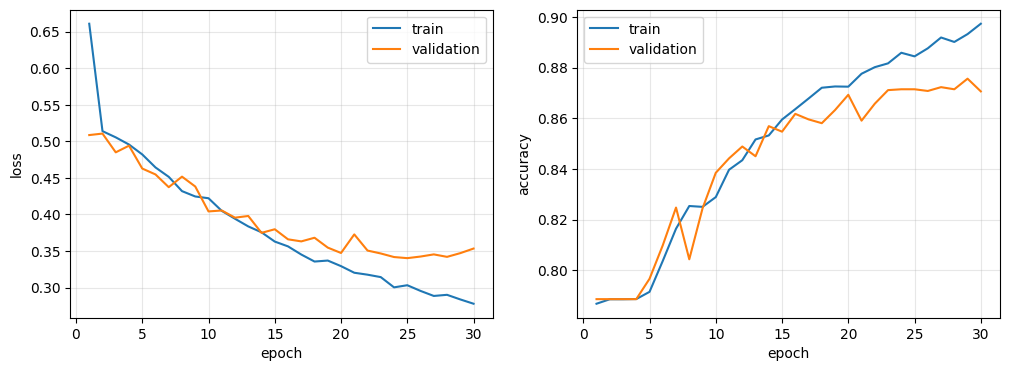

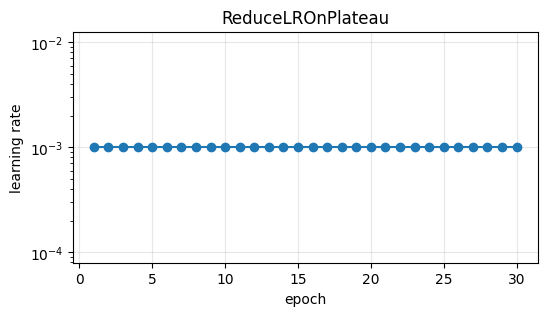

In [10]:
plot_history(history)
plt.figure(figsize=(6, 3))
plt.plot(range(1, len(history['lr']) + 1), history['lr'], marker='o')
plt.yscale('log'); plt.xlabel('epoch'); plt.ylabel('learning rate'); plt.grid(alpha=.3)
plt.title('ReduceLROnPlateau')
plt.show()

# (4) Evaluate trained model

In [11]:
score = evaluate(model, test_loader, loss_fn)
print('Test loss:', score[0])
print('Test accuracy:', score[1])

Test loss: 0.3401684214538288
Test accuracy: 0.8714812332439679


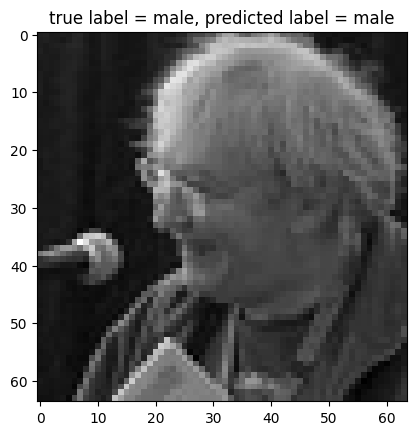

In [12]:
def int2gender(num):
    return 'female' if num == 0 else 'male'

# select a test image randomly
random_test_index = np.random.choice(x_test.shape[0], size=1)[0]
test_img = x_test[random_test_index]
test_label = y_test[random_test_index]
pred_label = np.argmax(predict(model, np.expand_dims(test_img, axis=0)))

plt.imshow(test_img[0], cmap='gray')
plt.title('true label = %s, predicted label = %s' % (int2gender(test_label), int2gender(pred_label)))
plt.show()